## __Skims Agentes__

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
DEMAND_TORONTO_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Demand'
SKIMS_TORONTO_FOLDER = r'/Users/jeannettearjona/Library/CloudStorage/OneDrive-InstitutoTecnologicoydeEstudiosSuperioresdeMonterrey/Modelación Urbana - Red Vial Guadalajara/Los Matrices'

periods = ["AP", "EA", "EM", "LM", "LN", "PP"]

### Lectura de matriz

In [15]:
def read_matrix(path, value_name):
    df = pd.read_csv(path)

    df = df.rename(columns={"Data": value_name})

    df["Origin"] = pd.to_numeric(df["Origin"])
    df["Destination"] = pd.to_numeric(df["Destination"])
    df[value_name] = pd.to_numeric(df[value_name], errors="coerce")

    return df[["Origin", "Destination", value_name]]

In [21]:
def prepare_prt_data(period):

    keys = ["Origin", "Destination"]

    # Leer demanda de autos (todos los periodos)
    auto = read_matrix(
        os.path.join(DEMAND_TORONTO_FOLDER, f"Auto{period}.mtx.csv"),
        "auto"
    )

    auto = auto[auto["auto"] > 0]

    # Para EM y LN solo hay demanda de autos
    if period in ["EM", "LN"]:
        demand = auto.copy()
        demand["demand"] = demand["auto"]

    # Para los demás periodos sumar Auto + Light + Heavy
    else:
        light = read_matrix(
            os.path.join(DEMAND_TORONTO_FOLDER, f"{period}TruckLight_pcu_ph.mtx.csv"),
            "light"
        )

        heavy = read_matrix(
            os.path.join(DEMAND_TORONTO_FOLDER, f"{period}TruckHeavy_pcu_ph.mtx.csv"),
            "heavy"
        )

        light = light[light["light"] > 0]
        heavy = heavy[heavy["heavy"] > 0]

        demand = (
            auto.merge(light, on=keys, how="outer", validate="one_to_one")
                .merge(heavy, on=keys, how="outer", validate="one_to_one")
        )

        demand[["auto", "light", "heavy"]] = (
            demand[["auto", "light", "heavy"]].fillna(0)
        )

        demand["demand"] = (
            demand["auto"] +
            demand["light"] +
            demand["heavy"]
        )

    # Leer skim de tiempos
    skim = read_matrix(
        os.path.join(SKIMS_TORONTO_FOLDER, period, "aivtt.mtx.csv"),
        "travel_time"
    )

    # Cruzar demanda con skim
    merged = demand.merge(
        skim,
        on=keys,
        how="left",
        validate="one_to_one"
    )

    # Diagnóstico de pares sin tiempo
    missing = merged["travel_time"].isna()

    print(
        f"{period}: {missing.sum():,} OD pairs without skim, "
        f"{merged.loc[missing, 'demand'].sum():,.2f} demand units"
    )

    # Conservar tiempos válidos
    merged = merged[
        (merged["travel_time"] > 0) &
        np.isfinite(merged["travel_time"])
    ].copy()

    merged["period"] = period

    return merged

AP: 0 OD pairs without skim, 0.00 demand units
EA: 0 OD pairs without skim, 0.00 demand units
EM: 0 OD pairs without skim, 0.00 demand units
LM: 0 OD pairs without skim, 0.00 demand units
LN: 0 OD pairs without skim, 0.00 demand units
PP: 0 OD pairs without skim, 0.00 demand units


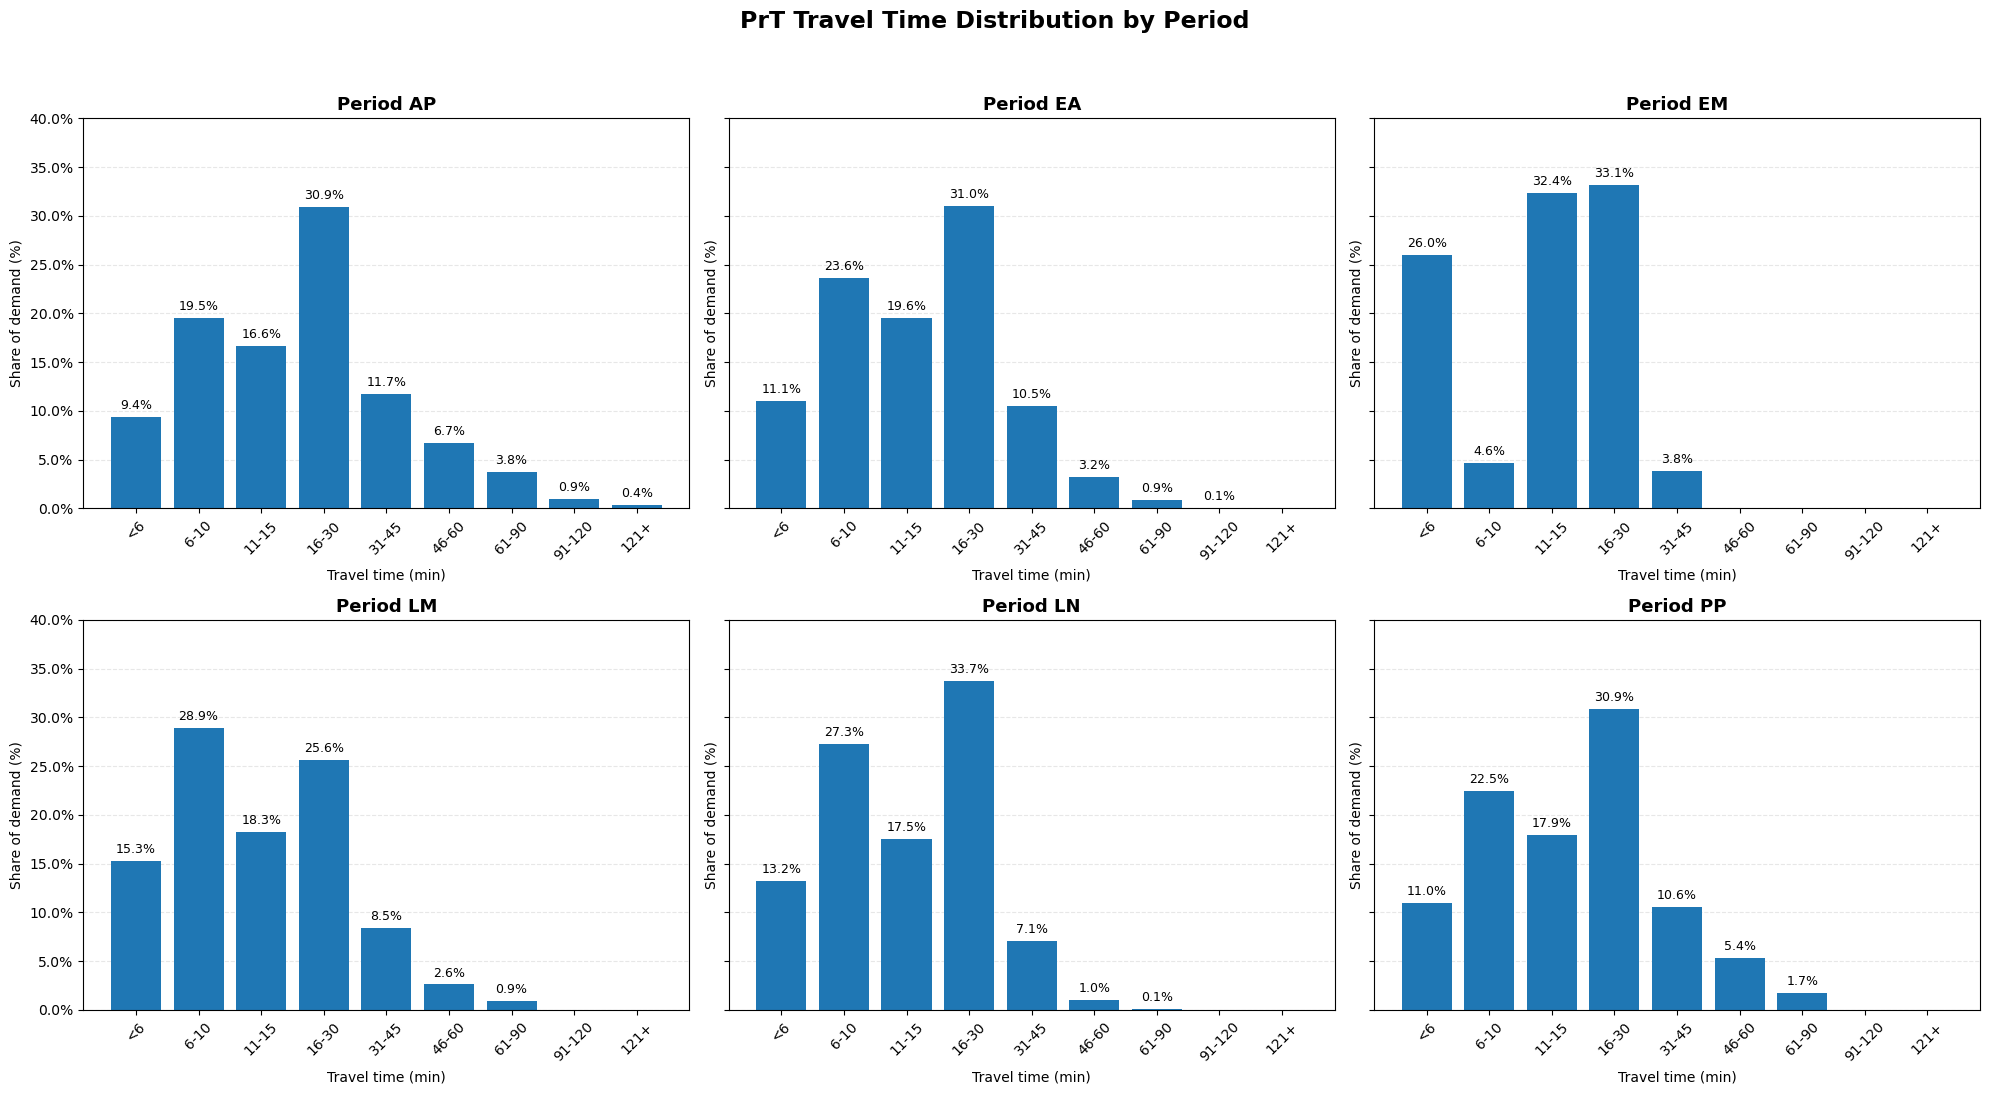

In [23]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

bins = [0, 6, 11, 16, 31, 46, 61, 91, 121, np.inf]

labels = [
    "<6", "6-10", "11-15", "16-30",
    "31-45", "46-60", "61-90", "91-120", "121+"
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(20, 11),
    sharey=True
)

max_pct = 0

for ax, period in zip(axes.flat, periods):

    df = prepare_prt_data(period)

    df["time_bin"] = pd.cut(
        df["travel_time"],
        bins=bins,
        labels=labels,
        right=False
    )

    distribution = (
        df.groupby("time_bin", observed=False)["demand"]
        .sum()
        .reindex(labels, fill_value=0)
    )

    percentages = distribution / distribution.sum() * 100

    max_pct = max(max_pct, percentages.max())

    bars = ax.bar(
        labels,
        percentages,
        width=0.8
    )

    # Porcentaje encima de cada barra
    for bar, pct in zip(bars, percentages):
        if pct > 0.05:
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.5,
                f"{pct:.1f}%",
                ha="center",
                va="bottom",
                fontsize=9
            )

    ax.set_title(f"Period {period}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Travel time (min)")
    ax.set_ylabel("Share of demand (%)")

    ax.tick_params(axis="x", rotation=45)

    # Líneas horizontales para facilitar la lectura
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)

# Escala compartida con espacio para las etiquetas
upper_limit = np.ceil((max_pct + 5) / 5) * 5

for ax in axes.flat:
    ax.set_ylim(0, upper_limit)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(5))
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=100))

plt.suptitle(
    "PrT Travel Time Distribution by Period",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()